# Data Visualization

This notebook uses `descriptors_v2.csv` produced by `audio_processing.ipynb` to plot the figures and summary statistics reported in the work.

In [40]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

# Helper

In [41]:
df = pd.read_csv('../data/descriptors_v2.csv')  

colors = {'wood': "#B47B52", 'abs': '#4682B4'}
notes = ['E4', 'F4', 'G4', 'A4']
methods = ['Bend', 'Natural']
descriptors = ['centroid', 'logattacktime', 'atk_time']
airflow_natural_direction = {
    'E4': 'blow',
    'G4': 'blow',
    'F4': 'draw',
    'A4': 'draw'
}

## Dataframe preparation

In [42]:
# creates a copy to avoid altering the original dataframe
df_combined = df.copy()
df_combined['method'] = df_combined['method'].str.capitalize()
df_combined['note_method'] = df_combined['note'] + '_' + df_combined['method']

# order from the lowest note (E4) to the highest note (A4)
x_order = []
for note in notes:
    for method in methods:
        x_order.append(f"{note}_{method}")

# map each note to its airflow direction (this is necessary because of natural notes)
df_combined['airflow_dir'] = df_combined['note'].map(airflow_natural_direction)

df_combined['method_direction'] = np.where(
    df_combined['method'] == 'Bend',
    'draw_bend',                            # we are just using draw bends
    'natural_' + df_combined['airflow_dir'] # natural notes are labeled by their blow/draw direction
)

In [43]:
def getCombinedGraph(y_var, str_variable, str_unit):
    plt.figure(figsize=(12, 6))

    ax = sns.boxplot(data=df_combined, 
                    x='note_method', 
                    y=y_var, 
                    hue='material', 
                    order=x_order,
                    palette=colors)

    method_labels = methods * len(notes)
    ax.set_xticks(ax.get_xticks())
    ax.set_xticklabels(method_labels)

    # inserts the corresponding pitch below each pair 
    for i, note in enumerate(notes):
        x_position = i * 2 + 0.5 
        ax.text(x_position, -0.05, note, transform=ax.get_xaxis_transform(), ha='center', va='top', fontsize=12)

    # handle graph labels and graph legend
    plt.xlabel('\n\nPitch and Production Method') 
    plt.ylabel(f'{str_variable} ({str_unit})')
    #plt.title(f'{str_variable}')

    handles, labels = ax.get_legend_handles_labels()
    graph_labels = []
    for label in labels:
        if label == 'wood':
            graph_labels.append('Wood')
        else:
            graph_labels.append('ABS Plastic')

    plt.legend(handles=handles, labels=graph_labels, title='Comb Material')

    # adjust and show graph
    plt.tight_layout()
    plt.show()

# Descriptors

## Spectral Centroid

Bending consistently lowers the spectral centroid relative to the note naturally produced equivalent, but the size of this shift depends on airflow direction:

- Blow notes (E4, G4) show a far larger gap than draw notes (F4, A4).
- Comb material, shows little visible effect. Wood and ABS plastic boxes largely overlap within each note/method pair.

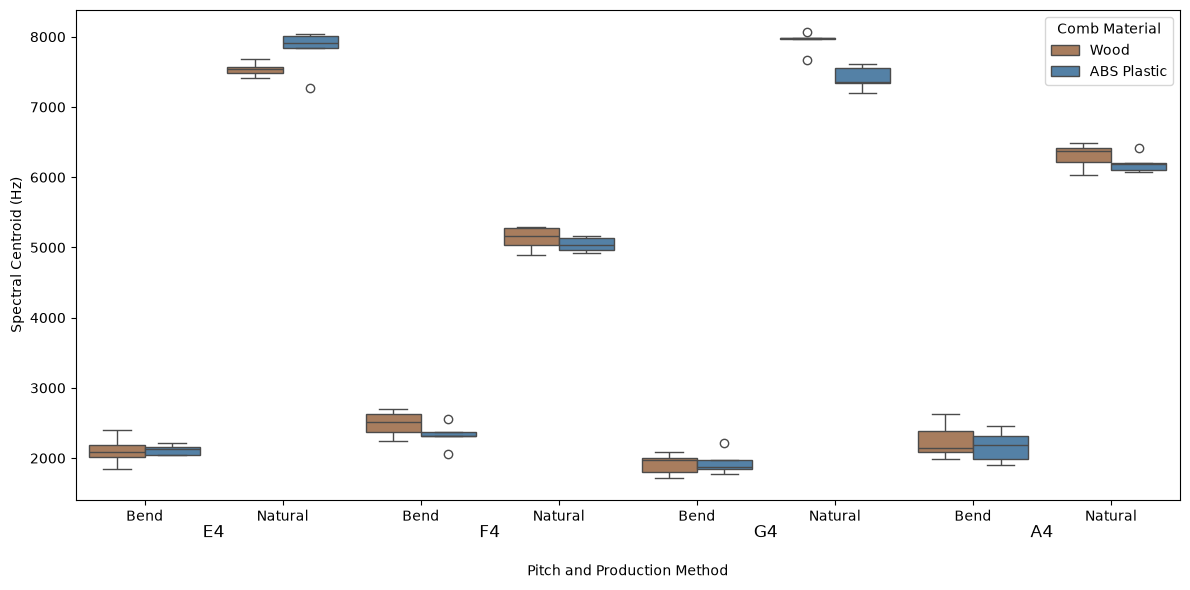

In [44]:
getCombinedGraph('centroid', 'Spectral Centroid', 'Hz')

## Log-Attacktime

Bending tends to produce faster attacks (more negative LAT) than the naturally produced equivalent.

A few recordings show a log-attacktime above zero (an attack time longer than one second) appearing in both natural F4 and bend G4 groups.
These points show up as outliers but were kept in the dataset rather than discarded to avoid introducing selection bias into the descriptive statistics and the PERMANOVA testing that follows.

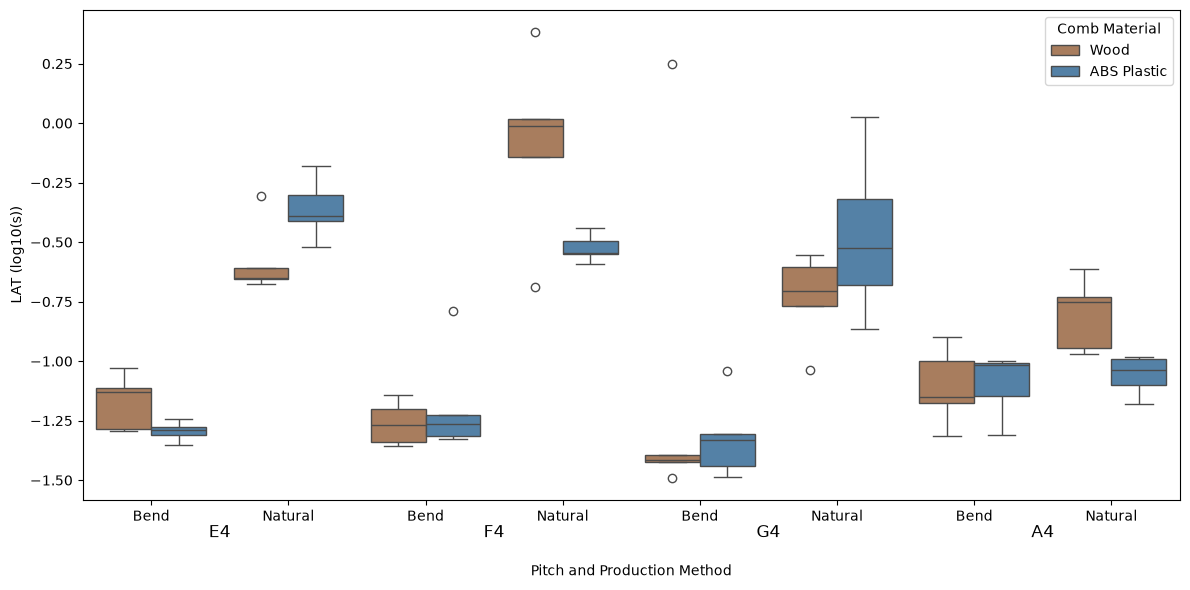

In [45]:
getCombinedGraph('logattacktime', 'LAT', 'log10(s)')

# Medians and IQR

In [46]:
# compute the median of each descriptors by the given variable(s)
def getMedians(variable, descriptors):
    print(f'\n{variable}')
    medians = df_combined.groupby(variable)[descriptors].median()
    display(medians.round(4))
    return medians

In [47]:
# compute the interquatile range of each descriptors by the given variable(s)
def getIQR(variable, descriptors):
    print(f'\n{variable}')
    q3 = df_combined.groupby(variable)[descriptors].quantile(0.75)
    q1 = df_combined.groupby(variable)[descriptors].quantile(0.25)
    iqr = q3 - q1
    display(iqr.round(4))
    return iqr

## Medians

Medians are computed at three levels: 
- by note, method, and material; 
- by note and method only (to see the production method effect); and
- by airflow direction (to check how blow/draw notes differ).

In [48]:
medians = getMedians(['note', 'method', 'material'], descriptors)
medians_notes_method = getMedians(['note', 'method'], descriptors)
medians_airflow = getMedians(['method_direction'], descriptors)


['note', 'method', 'material']


centroid  logattacktime  atk_time
note method  material                                    
A4   Bend    abs       2184.8363        -1.0157    0.0965
             wood      2150.7021        -1.1504    0.0707
     Natural abs       6184.9334        -1.0375    0.0917
             wood      6376.0581        -0.7495    0.1780
E4   Bend    abs       2128.9649        -1.2875    0.0516
             wood      2080.5771        -1.1289    0.0743
     Natural abs       7912.5979        -0.3922    0.4054
             wood      7534.7693        -0.6511    0.2233
F4   Bend    abs       2321.3849        -1.2631    0.0546
             wood      2520.4674        -1.2701    0.0537
     Natural abs       5040.4053        -0.5474    0.2835
             wood      5165.6841        -0.0104    0.9764
G4   Bend    abs       1877.7914        -1.3296    0.0468
             wood      1980.2243        -1.4136    0.0386
     Natural abs       7351.6777        -0.5225    0.3002
             wood      7984.4798        -0.7067    0.1965


['note', 'method']


centroid  logattacktime  atk_time
note method                                     
A4   Bend     2167.7692        -1.0819    0.0838
     Natural  6209.4662        -0.9775    0.1053
E4   Bend     2104.7710        -1.2802    0.0525
     Natural  7625.7578        -0.4644    0.3461
F4   Bend     2373.6638        -1.2666    0.0541
     Natural  5090.3272        -0.4681    0.3409
G4   Bend     1926.9978        -1.4046    0.0394
     Natural  7637.3938        -0.6421    0.2289


['method_direction']


,centroid,logattacktime,atk_time
method_direction,,,
draw_bend,2139.8335,-1.2733,0.0533
natural_blow,7637.3938,-0.5784,0.2645
natural_draw,5659.4441,-0.6513,0.2240


## IQR

The same groupings are repeated for the interquartile range, giving a sense of how much within group variability exists.

In [49]:
iqr = getIQR(['note', 'method', 'material'], descriptors)
iqr_notes_method = getIQR(['note', 'method'], descriptors,)
iqr_airflow = getIQR(['method_direction', 'material'], descriptors)


['note', 'method', 'material']


centroid  logattacktime  atk_time
note method  material                                   
A4   Bend    abs       326.2949         0.1410    0.0273
             wood      295.0700         0.1739    0.0330
     Natural abs        95.0181         0.1097    0.0227
             wood      202.2935         0.2128    0.0717
E4   Bend    abs       111.3329         0.0323    0.0038
             wood      181.1773         0.1725    0.0254
     Natural abs       170.3090         0.1056    0.1073
             wood       95.7273         0.0461    0.0249
F4   Bend    abs        61.4118         0.0872    0.0108
             wood      255.4015         0.1394    0.0172
     Natural abs       182.3499         0.0559    0.0387
             wood      238.5027         0.1600    0.3207
G4   Bend    abs       133.0026         0.1318    0.0129
             wood      194.8720         0.0276    0.0025
     Natural abs       217.4428         0.3611    0.2706
             wood       14.8673         0.1665    0.0793


['note', 'method']


centroid  logattacktime  atk_time
note method                                    
A4   Bend     350.2031         0.1662    0.0316
     Natural  286.8327         0.2277    0.0676
E4   Bend     139.6511         0.1343    0.0189
     Natural  400.9897         0.3125    0.2427
F4   Bend     229.3440         0.1169    0.0146
     Natural  188.7400         0.5059    0.6300
G4   Bend     180.4096         0.1223    0.0119
     Natural  579.4031         0.2242    0.1187


['method_direction', 'material']


centroid  logattacktime  atk_time
method_direction material                                    
draw_bend        abs        327.1199         0.1958    0.0279
                 wood       393.7865         0.2203    0.0299
natural_blow     abs        552.8773         0.2143    0.1920
                 wood       437.1417         0.0944    0.0485
natural_draw     abs       1099.2356         0.4781    0.1888
                 wood      1143.8930         0.7018    0.7324